<a href="https://colab.research.google.com/github/reginaldo-adsj/analise-mercado-imobiliario/blob/main/rpa_monitor_indicadores_bcb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import sqlite3

conn = sqlite3.connect('monitor_financeiro.db')
cursor = conn.cursor()

cursor.execute('''
CREATE TABLE IF NOT EXISTS historico_cotacoes (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    indicador TEXT NOT NULL,
    data_referencia TEXT NOT NULL,
    valor REAL NOT NULL,
    data_execucao_rpa TEXT NOT NULL
)
''')

conn.commit()
conn.close()

print("Banco e tabela prontos!")

Banco e tabela prontos!


In [33]:
import requests
import sqlite3
from datetime import datetime

def coletar_e_salvar_indicador(codigo_serie, nome_indicador, ultimos_n=5):
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo_serie}/dados/ultimos/{ultimos_n}?formato=json"
    headers = {"User-Agent": "Mozilla/5.0"}

    resposta = requests.get(url, headers=headers, timeout=10)
    resposta.raise_for_status()
    dados = resposta.json()

    conn = sqlite3.connect('monitor_financeiro.db')
    cursor = conn.cursor()

    cursor.execute('''
    CREATE TABLE IF NOT EXISTS historico_cotacoes (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        indicador TEXT NOT NULL,
        data_referencia TEXT NOT NULL,
        valor REAL NOT NULL,
        data_execucao_rpa TEXT NOT NULL
    )
    ''')

    data_execucao = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    inseridos = 0
    ignorados = 0

    for item in dados:
        cursor.execute('''
            SELECT id FROM historico_cotacoes
            WHERE indicador = ? AND data_referencia = ?
        ''', (nome_indicador, item['data']))

        if cursor.fetchone() is None:
            cursor.execute('''
                INSERT INTO historico_cotacoes (indicador, data_referencia, valor, data_execucao_rpa)
                VALUES (?, ?, ?, ?)
            ''', (nome_indicador, item['data'], float(item['valor']), data_execucao))
            inseridos += 1
        else:
            ignorados += 1

    conn.commit()
    conn.close()

    print(f"{nome_indicador} -> Inseridos: {inseridos} | Ignorados: {ignorados}")

coletar_e_salvar_indicador(1, 'Dolar_PTAX', ultimos_n=5)
coletar_e_salvar_indicador(11, 'Taxa_Selic', ultimos_n=5)

Dolar_PTAX -> Inseridos: 0 | Ignorados: 5
Taxa_Selic -> Inseridos: 0 | Ignorados: 5


In [34]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('monitor_financeiro.db')

query = '''
SELECT
    indicador,
    COUNT(*) AS total_registros,
    ROUND(MIN(valor), 4) AS menor_valor,
    ROUND(MAX(valor), 4) AS maior_valor,
    ROUND(AVG(valor), 4) AS media_periodo
FROM historico_cotacoes
GROUP BY indicador
'''

df_resumo = pd.read_sql_query(query, conn)
df_completo = pd.read_sql_query("SELECT * FROM historico_cotacoes", conn)

conn.close()

df_completo.to_excel("relatorio_cotacoes.xlsx", index=False)

print(df_resumo)
print("\nArquivo 'relatorio_cotacoes.xlsx' gerado com sucesso!")

    indicador  total_registros  menor_valor  maior_valor  media_periodo
0  Dolar_PTAX                5       5.6518       5.8889         5.7737
1  Taxa_Selic                5       0.0508       0.0508         0.0508

Arquivo 'relatorio_cotacoes.xlsx' gerado com sucesso!


In [35]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('monitor_financeiro.db')

query = '''
SELECT
    indicador,
    COUNT(*) AS total_registros,
    ROUND(MIN(valor), 4) AS menor_valor,
    ROUND(MAX(valor), 4) AS maior_valor,
    ROUND(AVG(valor), 4) AS media_periodo
FROM historico_cotacoes
GROUP BY indicador
'''

df_resumo = pd.read_sql_query(query, conn)
df_completo = pd.read_sql_query("SELECT * FROM historico_cotacoes", conn)

conn.close()

df_completo.to_excel("relatorio_cotacoes.xlsx", index=False)

print(df_resumo)
print("\nArquivo 'relatorio_cotacoes.xlsx' gerado com sucesso!")

    indicador  total_registros  menor_valor  maior_valor  media_periodo
0  Dolar_PTAX                5       5.6518       5.8889         5.7737
1  Taxa_Selic                5       0.0508       0.0508         0.0508

Arquivo 'relatorio_cotacoes.xlsx' gerado com sucesso!


In [36]:
import os
import sqlite3
import pandas as pd
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side

os.chdir('/content')

conn = sqlite3.connect('/content/monitor_financeiro.db')

query_resumo = '''
SELECT
    indicador,
    COUNT(*) AS total_registros,
    ROUND(MIN(valor), 4) AS menor_valor,
    ROUND(MAX(valor), 4) AS maior_valor,
    ROUND(AVG(valor), 4) AS media_periodo
FROM historico_cotacoes
GROUP BY indicador
'''

df_resumo = pd.read_sql_query(query_resumo, conn)
df_completo = pd.read_sql_query("SELECT * FROM historico_cotacoes ORDER BY id DESC", conn)

conn.close()

caminho_excel = '/content/relatorio_cotacoes.xlsx'

with pd.ExcelWriter(caminho_excel, engine='openpyxl') as writer:
    df_resumo.to_excel(writer, sheet_name='Resumo_Indicadores', index=False)
    df_completo.to_excel(writer, sheet_name='Historico_Detalhado', index=False)

wb = load_workbook(caminho_excel)

estilo_cabecalho_fonte = Font(name='Calibri', size=11, bold=True, color='FFFFFF')
estilo_cabecalho_preenchimento = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid')
estilo_alinhamento_cabecalho = Alignment(horizontal='center', vertical='center')

borda_fina = Side(border_style='thin', color='D9D9D9')
estilo_borda = Border(left=borda_fina, right=borda_fina, top=borda_fina, bottom=borda_fina)

for nome_aba in wb.sheetnames:
    ws = wb[nome_aba]
    ws.freeze_panes = 'A2'

    for celula in ws[1]:
        celula.font = estilo_cabecalho_fonte
        celula.fill = estilo_cabecalho_preenchimento
        celula.alignment = estilo_alinhamento_cabecalho
        celula.border = estilo_borda

    for linha in ws.iter_rows(min_row=2, max_row=ws.max_row, min_col=1, max_col=ws.max_column):
        for celula in linha:
            celula.border = estilo_borda
            if isinstance(celula.value, (int, float)):
                celula.alignment = Alignment(horizontal='right', vertical='center')
                if not isinstance(celula.value, int) or celula.column_letter != 'A':
                    celula.number_format = '#,##0.0000'
            else:
                celula.alignment = Alignment(horizontal='left', vertical='center')

    for coluna in ws.columns:
        maior_tamanho = max(len(str(celula.value or '')) for celula in coluna)
        nome_coluna = coluna[0].column_letter
        ws.column_dimensions[nome_coluna].width = maior_tamanho + 6

wb.save(caminho_excel)
print("Planilha estilizada salva em /content/relatorio_cotacoes.xlsx!")

Planilha estilizada salva em /content/relatorio_cotacoes.xlsx!


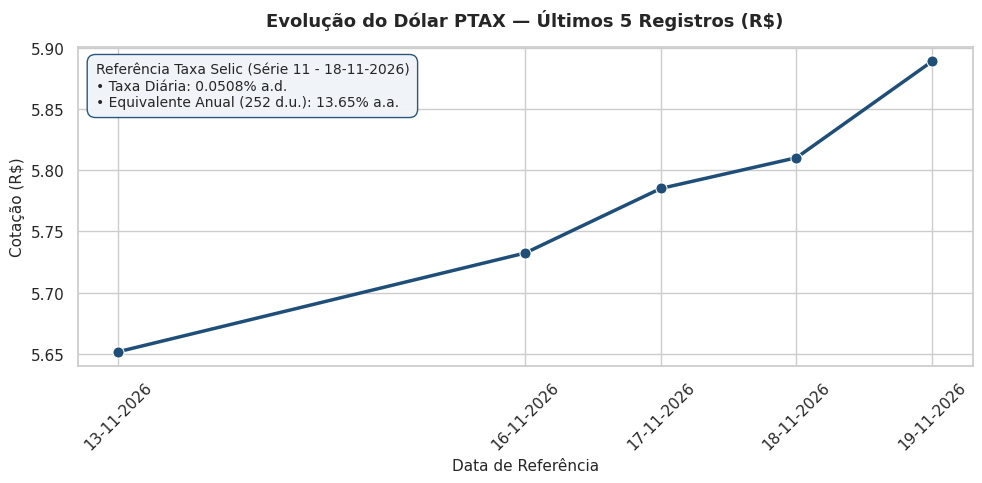

    indicador  total_registros  menor_valor  maior_valor  media_5_dias
0  Dolar_PTAX                5       5.6518       5.8889        5.7737
1  Taxa_Selic                5       0.0508       0.0508        0.0508


In [38]:
import os
import sqlite3
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side

os.chdir('/content')

def buscar_ultimos_dias_bcb(codigo_serie, nome_indicador, ultimos_n=5):
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo_serie}/dados/ultimos/{ultimos_n}?formato=json"
    headers = {"User-Agent": "Mozilla/5.0"}

    resposta = requests.get(url, headers=headers, timeout=10)
    resposta.raise_for_status()
    dados = resposta.json()

    data_execucao = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    linhas = []

    for item in dados:
        linhas.append({
            'indicador': nome_indicador,
            'data_referencia': item['data'],
            'valor': float(item['valor']),
            'data_execucao_rpa': data_execucao
        })

    return pd.DataFrame(linhas)

df_dolar = buscar_ultimos_dias_bcb(1, 'Dolar_PTAX', ultimos_n=5)
df_selic = buscar_ultimos_dias_bcb(11, 'Taxa_Selic', ultimos_n=5)

df_atual = pd.concat([df_dolar, df_selic], ignore_index=True)

conn = sqlite3.connect('/content/monitor_financeiro.db')
cursor = conn.cursor()

cursor.execute('''
CREATE TABLE IF NOT EXISTS historico_cotacoes (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    indicador TEXT NOT NULL,
    data_referencia TEXT NOT NULL,
    valor REAL NOT NULL,
    data_execucao_rpa TEXT NOT NULL
)
''')

cursor.execute('DELETE FROM historico_cotacoes')

for _, row in df_atual.iterrows():
    cursor.execute('''
        INSERT INTO historico_cotacoes (indicador, data_referencia, valor, data_execucao_rpa)
        VALUES (?, ?, ?, ?)
    ''', (row['indicador'], row['data_referencia'], row['valor'], row['data_execucao_rpa']))

conn.commit()

query_resumo = '''
SELECT
    indicador,
    COUNT(*) AS total_registros,
    ROUND(MIN(valor), 4) AS menor_valor,
    ROUND(MAX(valor), 4) AS maior_valor,
    ROUND(AVG(valor), 4) AS media_5_dias
FROM historico_cotacoes
GROUP BY indicador
'''

df_resumo = pd.read_sql_query(query_resumo, conn)
df_detalhado = pd.read_sql_query("SELECT * FROM historico_cotacoes ORDER BY id ASC", conn)
conn.close()

caminho_excel = '/content/relatorio_cotacoes.xlsx'

with pd.ExcelWriter(caminho_excel, engine='openpyxl') as writer:
    df_resumo.to_excel(writer, sheet_name='Resumo_5_Dias', index=False)
    df_detalhado.to_excel(writer, sheet_name='Ultimos_5_Registros', index=False)

wb = load_workbook(caminho_excel)

fonte_cab = Font(name='Calibri', size=11, bold=True, color='FFFFFF')
fill_cab = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid')
borda_fina = Side(border_style='thin', color='D9D9D9')
borda = Border(left=borda_fina, right=borda_fina, top=borda_fina, bottom=borda_fina)

for nome_aba in wb.sheetnames:
    ws = wb[nome_aba]
    ws.freeze_panes = 'A2'

    for celula in ws[1]:
        celula.font = fonte_cab
        celula.fill = fill_cab
        celula.alignment = Alignment(horizontal='center', vertical='center')
        celula.border = borda

    for linha in ws.iter_rows(min_row=2, max_row=ws.max_row, min_col=1, max_col=ws.max_column):
        for celula in linha:
            celula.border = borda
            if isinstance(celula.value, (int, float)):
                celula.alignment = Alignment(horizontal='right', vertical='center')
                if not isinstance(celula.value, int) or celula.column_letter != 'A':
                    celula.number_format = '#,##0.0000'
            else:
                celula.alignment = Alignment(horizontal='left', vertical='center')

    for coluna in ws.columns:
        maior_tamanho = max(len(str(celula.value or '')) for celula in coluna)
        ws.column_dimensions[coluna[0].column_letter].width = maior_tamanho + 6

wb.save(caminho_excel)

df_dolar_plot = df_detalhado[df_detalhado['indicador'] == 'Dolar_PTAX'].copy()
df_dolar_plot['data_dt'] = pd.to_datetime(df_dolar_plot['data_referencia'], format='%d/%m/%Y')
df_dolar_plot = df_dolar_plot.sort_values('data_dt')

df_selic_plot = df_detalhado[df_detalhado['indicador'] == 'Taxa_Selic'].copy()
df_selic_plot['data_dt'] = pd.to_datetime(df_selic_plot['data_referencia'], format='%d/%m/%Y')
df_selic_plot = df_selic_plot.sort_values('data_dt')

ultima_selic = df_selic_plot.iloc[-1]['valor']
data_selic = df_selic_plot.iloc[-1]['data_dt'].strftime('%d-%m-%Y')
selic_anual_aprox = ((1 + (ultima_selic / 100)) ** 252 - 1) * 100

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=df_dolar_plot,
    x='data_dt',
    y='valor',
    marker='o',
    markersize=8,
    linewidth=2.5,
    color='#1f4e78',
    ax=ax
)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
ax.set_xticks(df_dolar_plot['data_dt'])
ax.set_title('Evolução do Dólar PTAX — Últimos 5 Registros (R$)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Cotação (R$)', fontsize=11)
ax.set_xlabel('Data de Referência', fontsize=11)

texto_selic = (
    f"Referência Taxa Selic (Série 11 - {data_selic})\n"
    f"• Taxa Diária: {ultima_selic:.4f}% a.d.\n"
    f"• Equivalente Anual (252 d.u.): {selic_anual_aprox:.2f}% a.a."
)

ax.text(
    0.02, 0.95, texto_selic,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='#f0f4f8', edgecolor='#1f4e78', alpha=0.95)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('/content/grafico_dolar_selic.png', dpi=150)
plt.show()

print(df_resumo)